# 02 — Exploratory data analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/hdi_classification_2023.csv")

NUM = ["GDP_growth", "Inflation", "Unemployment", "Infant_mortality", "Electricity_access",
       "Internet_users", "Agriculture_VA", "Industry_VA", "Trade"]
CAT = ["Region", "DominantSector"]

## 1. Overview

In [2]:
df.shape

(193, 16)

In [3]:
df[NUM + CAT].dtypes

GDP_growth            float64
Inflation             float64
Unemployment          float64
Infant_mortality      float64
Electricity_access    float64
Internet_users        float64
Agriculture_VA        float64
Industry_VA           float64
Trade                 float64
Region                    str
DominantSector            str
dtype: object

In [4]:
df["HDI_class"].value_counts()

HDI_class
Medium/High    93
Very High      74
Low            26
Name: count, dtype: int64

In [5]:
df[NUM].describe().T

,count,mean,std,min,25%,50%,75%,max
GDP_growth,188.0,2.957387,4.623745,-29.433272,1.173114,3.136997,4.951812,33.795011
Inflation,175.0,10.253156,20.815756,-4.644709,3.590991,5.865719,9.302624,221.341644
Unemployment,176.0,6.765494,5.595546,0.130000,3.117500,5.159500,8.332500,34.610000
Infant_mortality,191.0,19.354450,17.381980,1.300000,5.100000,13.200000,30.050000,71.900000
Electricity_access,193.0,87.054922,23.223905,5.400000,85.300000,100.000000,100.000000,100.000000
Internet_users,179.0,71.445195,25.363078,7.172300,58.944351,81.580597,90.962952,100.000000
Agriculture_VA,183.0,10.164048,10.002369,0.015094,2.436646,6.661449,16.616926,43.988089
Industry_VA,183.0,26.185331,11.981739,2.086302,18.437939,24.563966,32.061771,78.899528
Trade,167.0,94.454333,61.409560,2.473729,51.617171,81.962548,115.979792,402.566968


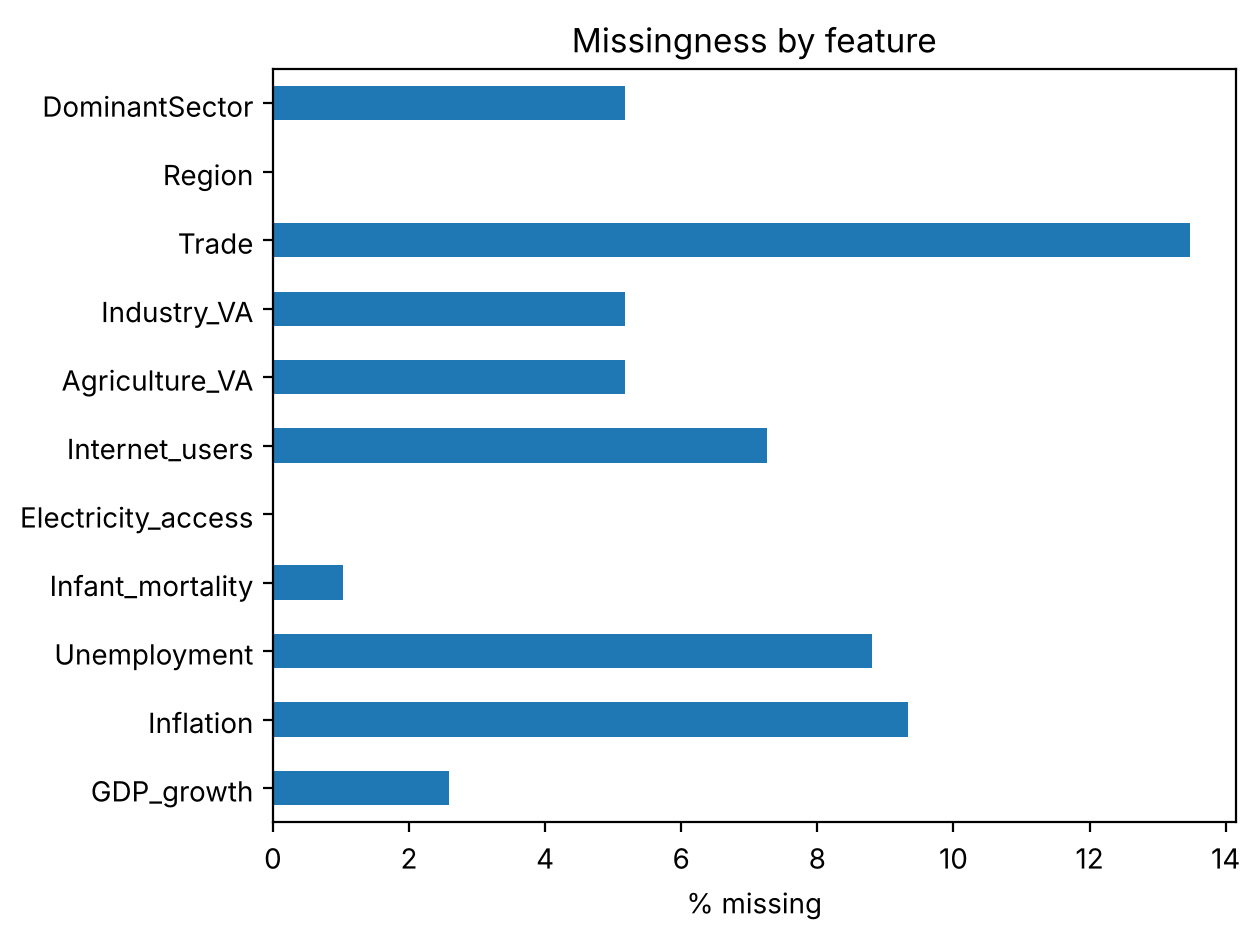

In [6]:
missing = df[NUM + CAT].isna().mean() * 100
missing.plot.barh()
plt.xlabel("% missing")
plt.title("Missingness by feature")
plt.tight_layout()
plt.savefig("../figures/missing_by_feature.png", dpi=200)
plt.show()

In [7]:
missing_by_class = df[NUM + CAT].isna().groupby(df["HDI_class"]).mean() * 100
missing_by_class

,GDP_growth,Inflation,Unemployment,Infant_mortality,Electricity_access,Internet_users,Agriculture_VA,Industry_VA,Trade,Region,DominantSector
HDI_class,,,,,,,,,,,
Low,11.538462,19.230769,3.846154,0.000000,0.0,19.230769,15.384615,15.384615,19.230769,0.0,15.384615
Medium/High,1.075269,11.827957,10.752688,0.000000,0.0,9.677419,4.301075,4.301075,15.053763,0.0,4.301075
Very High,1.351351,2.702703,8.108108,2.702703,0.0,0.000000,2.702703,2.702703,9.459459,0.0,2.702703


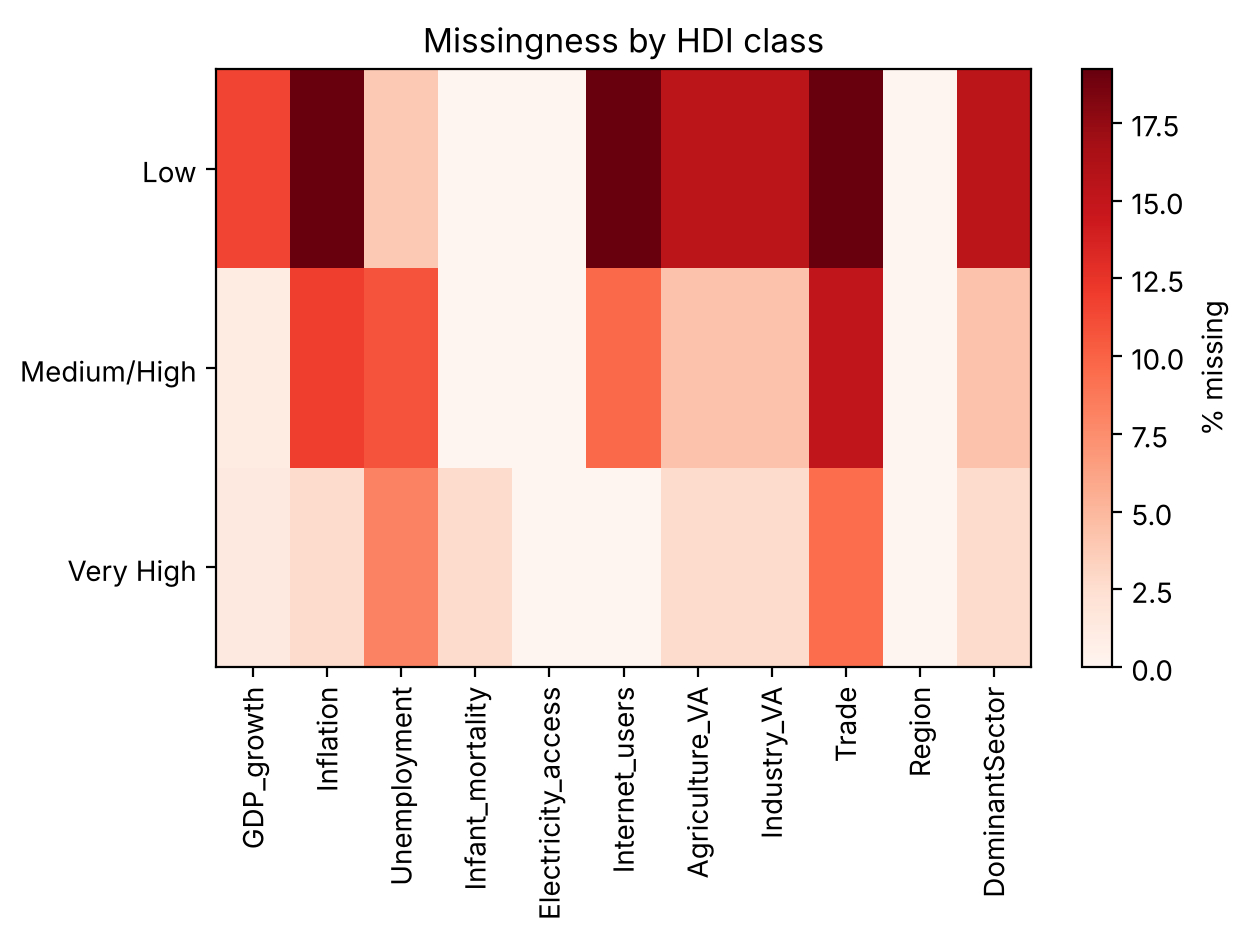

In [8]:
plt.imshow(missing_by_class, cmap="Reds", aspect="auto")
plt.xticks(range(len(NUM + CAT)), NUM + CAT, rotation=90)
plt.yticks(range(3), missing_by_class.index)
plt.colorbar(label="% missing")
plt.title("Missingness by HDI class")
plt.tight_layout()
plt.savefig("../figures/missing_by_class.png", dpi=200)
plt.show()

## 2. Distributions and outliers

In [9]:
df[NUM].skew()

GDP_growth           -0.691052
Inflation             7.466311
Unemployment          2.088704
Infant_mortality      1.138556
Electricity_access   -1.833393
Internet_users       -0.990403
Agriculture_VA        1.149977
Industry_VA           1.176985
Trade                 2.218259
dtype: float64

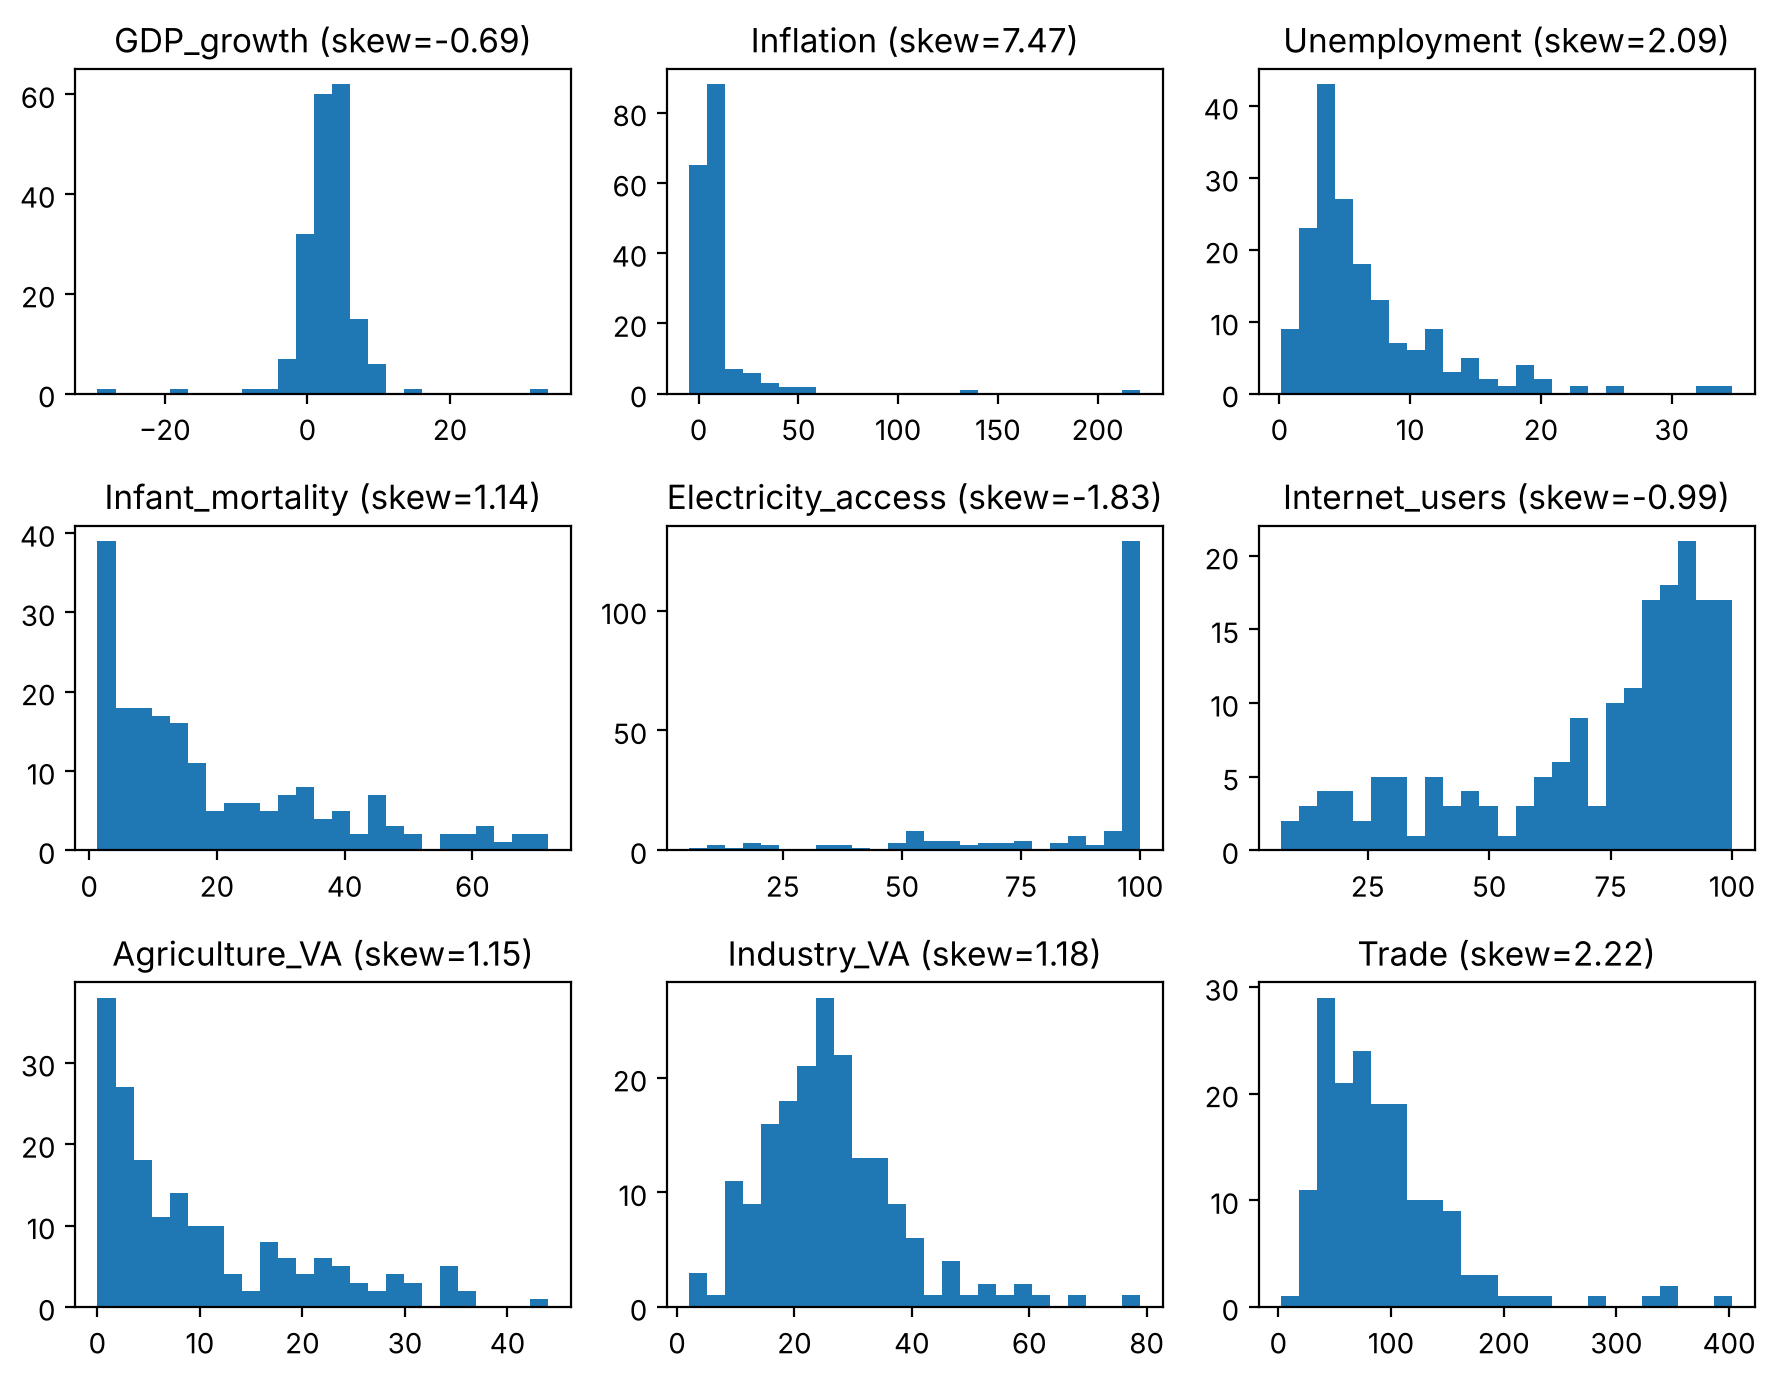

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(9, 7))
for ax, col in zip(axes.flatten(), NUM):
    ax.hist(df[col].dropna(), bins=25)
    ax.set_title(f"{col} (skew={df[col].skew():.2f})")
plt.tight_layout()
plt.savefig("../figures/histograms.png", dpi=200)
plt.show()

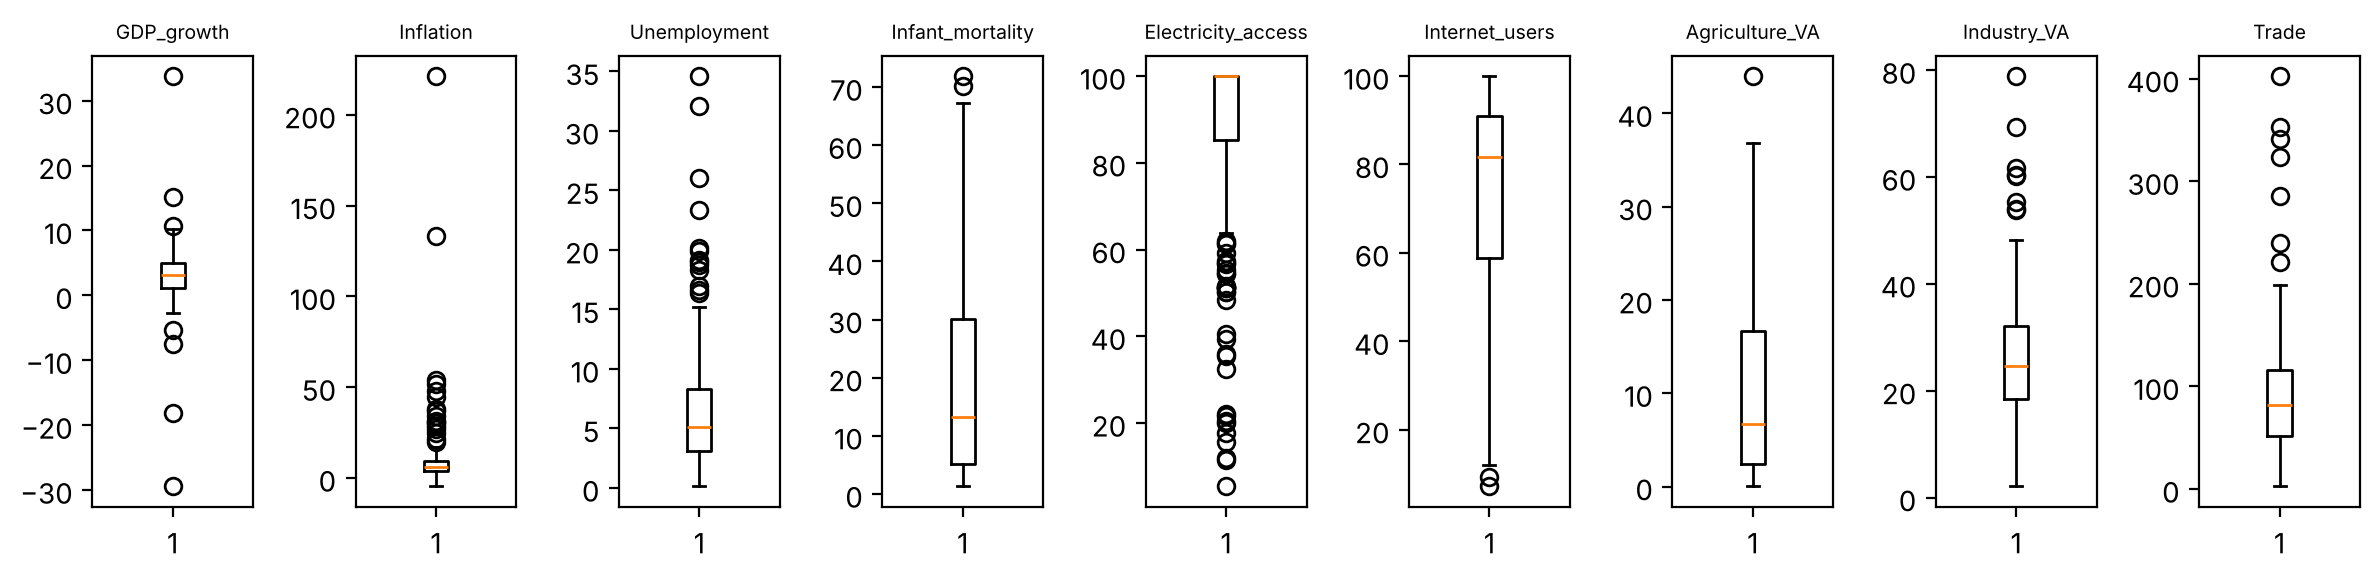

In [11]:
fig, axes = plt.subplots(1, 9, figsize=(12, 3))
for ax, col in zip(axes, NUM):
    ax.boxplot(df[col].dropna())
    ax.set_title(col, fontsize=7)
plt.tight_layout()
plt.savefig("../figures/boxplots.png", dpi=200)
plt.show()

In [12]:
# most extreme countries for the most skewed indicators
df.nlargest(5, "Inflation")[["Country", "Inflation"]]

,Country,Inflation
97,Lebanon,221.341644
5,Argentina,133.488936
176,Türkiye,53.859408
160,Suriname,51.587316
153,Sierra Leone,47.642873


In [13]:
df.nlargest(3, "GDP_growth")[["Country", "GDP_growth"]]

,Country,GDP_growth
71,Guyana,33.795011
188,Samoa,15.233606
115,Malta,10.634056


In [14]:
df.nsmallest(3, "GDP_growth")[["Country", "GDP_growth"]]

,Country,GDP_growth
149,Sudan,-29.433272
172,Timor-Leste,-18.135905
67,Equatorial Guinea,-7.425055


In [15]:
df.nlargest(5, "Trade")[["Country", "Trade"]]

,Country,Trade
105,Luxembourg,402.566968
72,"Hong Kong SAR, China",353.194609
155,San Marino,340.983400
151,Singapore,323.701220
45,Djibouti,285.902044


In [16]:
# implausible entries: percentages below 0 or above 100
pct = ["Unemployment", "Electricity_access", "Internet_users", "Agriculture_VA", "Industry_VA"]
(df[pct] < 0).sum() + (df[pct] > 100).sum()

Unemployment          0
Electricity_access    0
Internet_users        0
Agriculture_VA        0
Industry_VA           0
dtype: int64

No implausible entries were found. The extreme values (e.g. Lebanon and Argentina inflation, Guyana growth, Sudan contraction, Luxembourg trade) are real 2023 events, so they are kept and no transformation is applied. Trees are not affected by monotone transformations, and the features are standardised for logistic regression and PCA.

## 3. Indicators by HDI class

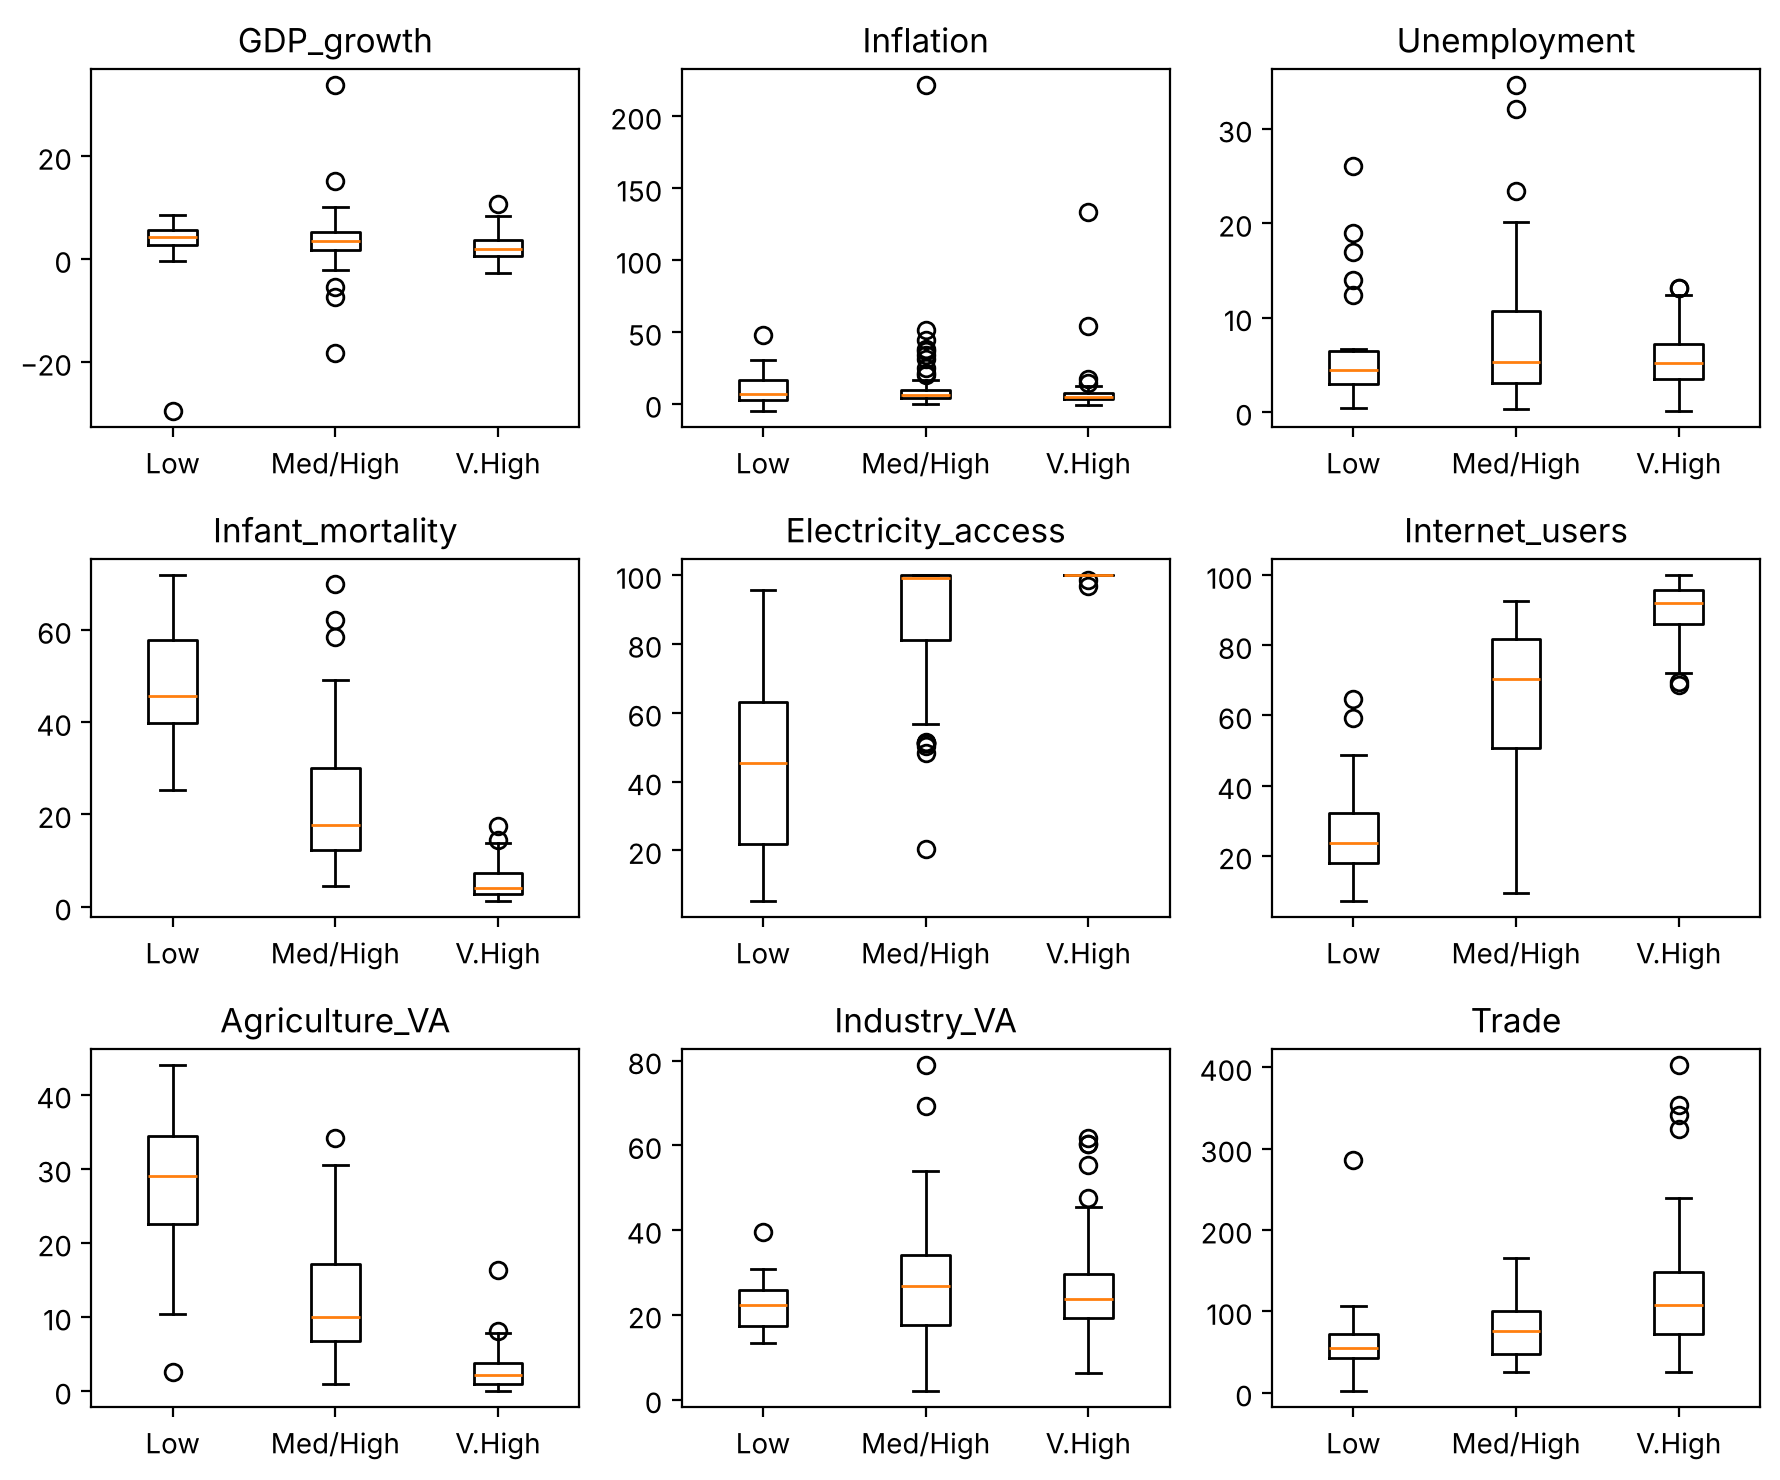

In [17]:
classes = ["Low", "Medium/High", "Very High"]
fig, axes = plt.subplots(3, 3, figsize=(9, 7.5))
for ax, col in zip(axes.flatten(), NUM):
    data = [df[df["HDI_class"] == c][col].dropna() for c in classes]
    ax.boxplot(data)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Low", "Med/High", "V.High"])
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../figures/boxplots_by_class.png", dpi=200)
plt.show()

In [18]:
df.groupby("HDI_class")[NUM].median().T

HDI_class,Low,Medium/High,Very High
GDP_growth,4.257431,3.528440,1.953086
Inflation,7.126975,6.026635,5.033869
Unemployment,4.469000,5.316000,5.224000
Infant_mortality,45.700000,17.700000,4.000000
Electricity_access,45.400000,99.300000,100.000000
Internet_users,23.713600,70.430752,92.216438
Agriculture_VA,28.961000,9.920603,2.139215
Industry_VA,22.210355,26.790780,23.694701
Trade,55.286797,76.173458,107.277802


## 4. Correlations

In [19]:
corr = df[NUM].corr()
corr.round(2)

,GDP_growth,Inflation,Unemployment,Infant_mortality,Electricity_access,Internet_users,Agriculture_VA,Industry_VA,Trade
GDP_growth,1.00,-0.11,0.08,0.07,-0.07,-0.19,0.06,0.11,0.03
Inflation,-0.11,1.00,0.03,0.04,-0.02,-0.03,0.05,-0.13,-0.13
Unemployment,0.08,0.03,1.00,0.15,-0.03,-0.00,-0.19,0.05,0.05
Infant_mortality,0.07,0.04,0.15,1.00,-0.79,-0.83,0.74,0.00,-0.33
Electricity_access,-0.07,-0.02,-0.03,-0.79,1.00,0.85,-0.68,-0.00,0.25
Internet_users,-0.19,-0.03,-0.00,-0.83,0.85,1.00,-0.82,0.13,0.39
Agriculture_VA,0.06,0.05,-0.19,0.74,-0.68,-0.82,1.00,-0.16,-0.44
Industry_VA,0.11,-0.13,0.05,0.00,-0.00,0.13,-0.16,1.00,-0.07
Trade,0.03,-0.13,0.05,-0.33,0.25,0.39,-0.44,-0.07,1.00


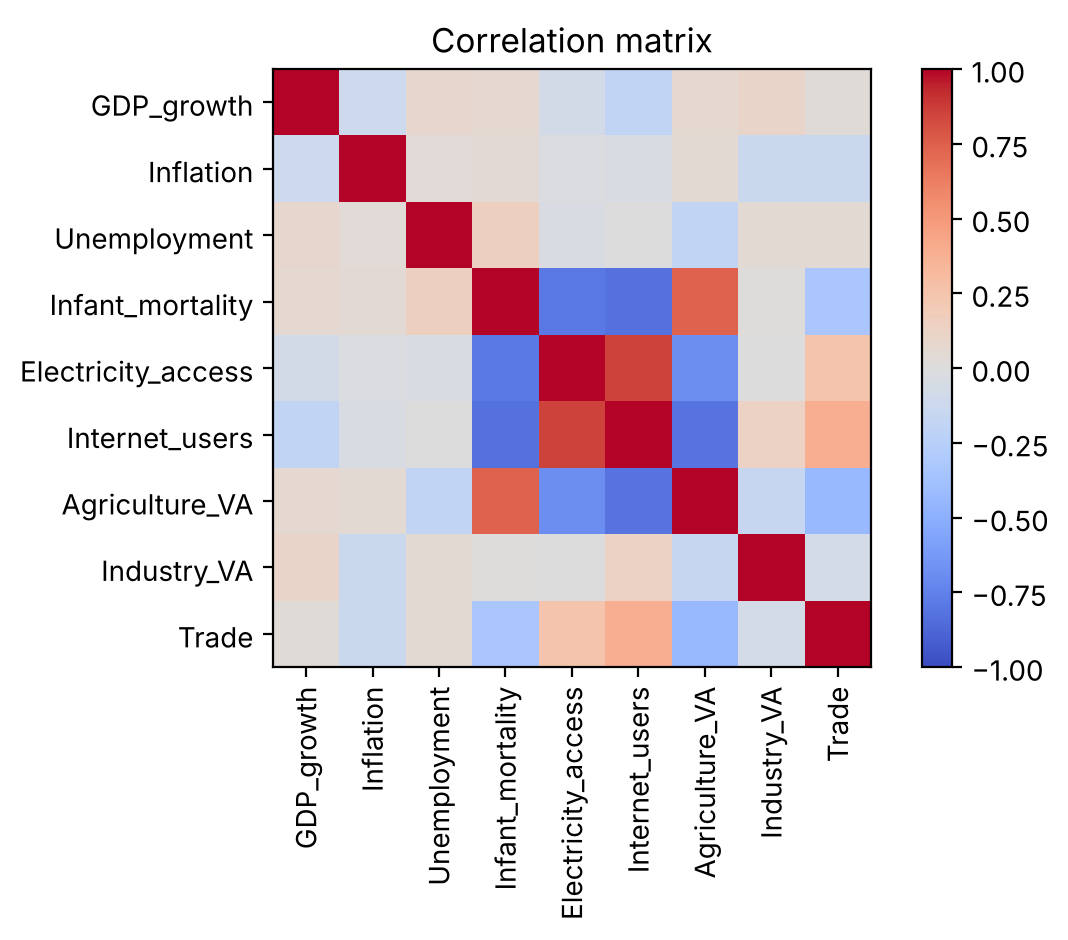

In [20]:
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(NUM)), NUM, rotation=90)
plt.yticks(range(len(NUM)), NUM)
plt.colorbar()
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("../figures/correlation_matrix.png", dpi=200)
plt.show()

## 5. Categorical variables

In [21]:
pd.crosstab(df["Region"], df["HDI_class"])

HDI_class,Low,Medium/High,Very High
Region,,,
East Asia & Pacific,0,22,8
Europe & Central Asia,0,7,44
Latin America & Caribbean,0,23,10
Middle East & North Africa,4,11,8
North America,0,0,2
South Asia,0,6,0
Sub-Saharan Africa,22,24,2


In [22]:
pd.crosstab(df["Region"], df["HDI_class"], normalize="index").round(2)

HDI_class,Low,Medium/High,Very High
Region,,,
East Asia & Pacific,0.00,0.73,0.27
Europe & Central Asia,0.00,0.14,0.86
Latin America & Caribbean,0.00,0.70,0.30
Middle East & North Africa,0.17,0.48,0.35
North America,0.00,0.00,1.00
South Asia,0.00,1.00,0.00
Sub-Saharan Africa,0.46,0.50,0.04


In [23]:
sector = df["DominantSector"].fillna("Missing")
pd.crosstab(sector, df["HDI_class"])

HDI_class,Low,Medium/High,Very High
DominantSector,,,
Agriculture,2,0,0
Industry,0,4,4
Missing,4,4,2
Services,20,85,68


In [24]:
pd.crosstab(sector, df["HDI_class"], normalize="index").round(2)

HDI_class,Low,Medium/High,Very High
DominantSector,,,
Agriculture,1.00,0.00,0.00
Industry,0.00,0.50,0.50
Missing,0.40,0.40,0.20
Services,0.12,0.49,0.39


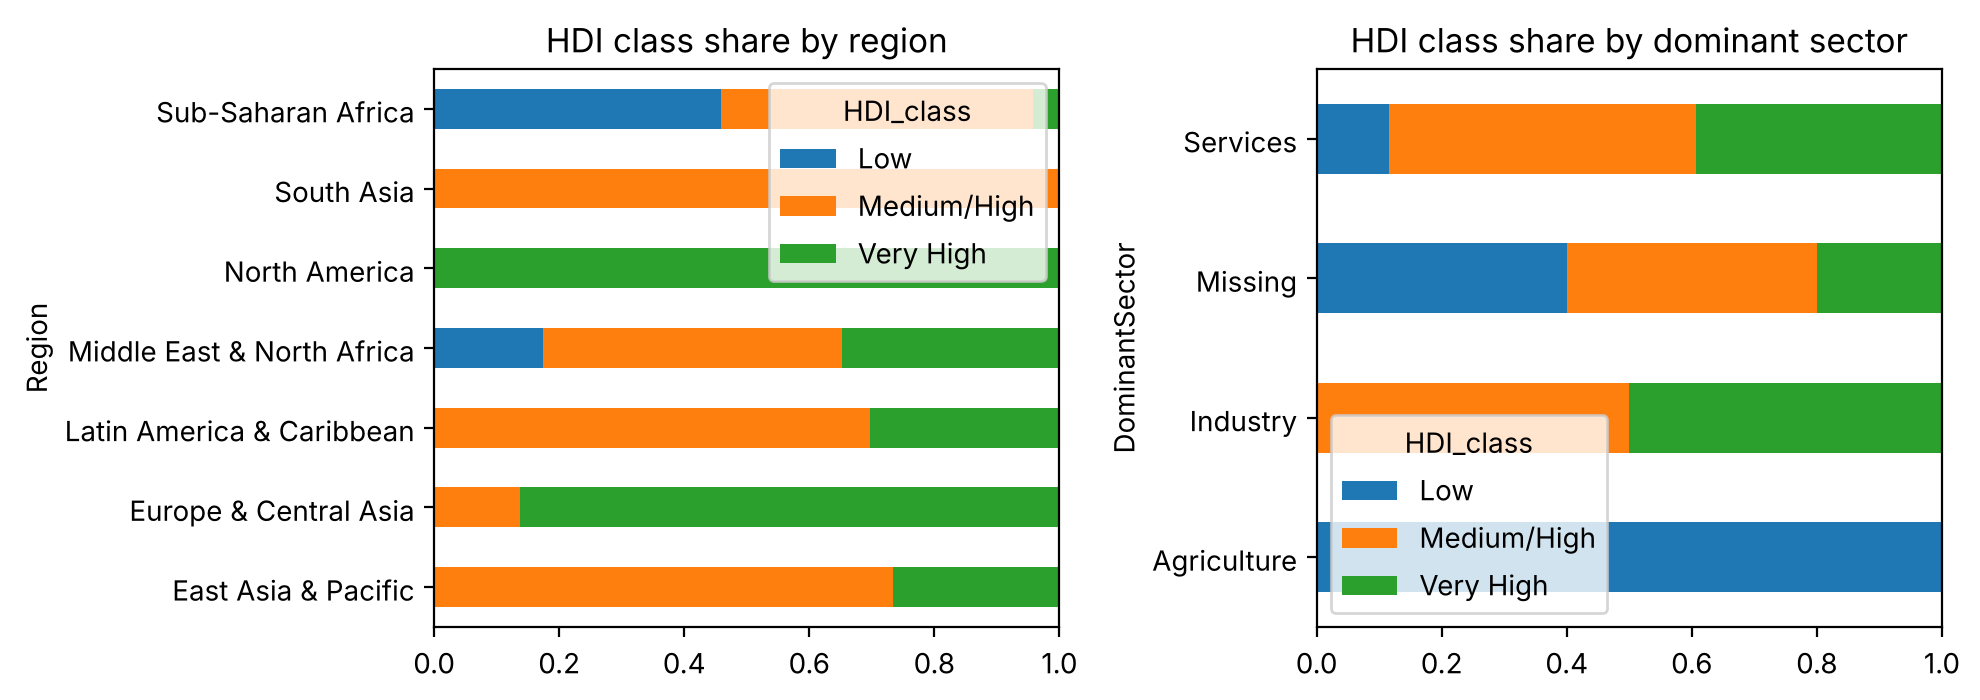

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
pd.crosstab(df["Region"], df["HDI_class"], normalize="index").plot.barh(stacked=True, ax=axes[0])
pd.crosstab(sector, df["HDI_class"], normalize="index").plot.barh(stacked=True, ax=axes[1])
axes[0].set_title("HDI class share by region")
axes[1].set_title("HDI class share by dominant sector")
plt.tight_layout()
plt.savefig("../figures/categorical_by_class.png", dpi=200)
plt.show()

## 6. Missingness vs HDI class

In [26]:
df["n_missing"] = df[NUM + CAT].isna().sum(axis=1)
df["any_missing"] = df["n_missing"] > 0
df.groupby("HDI_class")["any_missing"].mean()

HDI_class
Low            0.346154
Medium/High    0.333333
Very High      0.162162
Name: any_missing, dtype: float64

In [27]:
df[df["n_missing"] >= 3][["Country", "HDI_class", "n_missing"]].sort_values("n_missing", ascending=False)

,Country,HDI_class,n_missing
52,Eritrea,Low,7
166,Syrian Arab Republic,Medium/High,7
177,Tuvalu,Medium/High,7
189,"Yemen, Rep.",Low,7
158,South Sudan,Low,6
101,Liechtenstein,Very High,5
131,Naoero,Medium/High,5
185,"Venezuela, RB",Medium/High,4
156,"Somalia, Fed. Rep.",Low,4
3,Andorra,Very High,3


35% of Low countries have at least one missing value, compared with 16% of Very High countries. Missingness is therefore related to development level (not completely at random), so imputed values are least reliable for the poorest and conflict-affected countries.